In [33]:
import datetime as dt  
from py_eddy_tracker.dataset.grid import RegularGridDataset
from py_eddy_tracker.featured_tracking.area_tracker import AreaTracker
from py_eddy_tracker.gui import GUI
from py_eddy_tracker.tracking import Correspondances
from matplotlib import pyplot as plt
import numpy as np
import os
import sys
from netCDF4 import Dataset
from time import ctime


In [16]:

dirin        = './Data/original/'# 输入目录。这是包含输入文件的目录的路径。
dirout       = './Data/output/'#  输出目录。这是结果文件和图像将要保存的目录的路径。
pattern      = 'XXXXXXXX'# 文件模式的占位符。在文件模式中指定日期的占位符。
filepattern  = np.str_('dt_global_twosat_phy_l4_XXXXXXXX_vDT2021.nc')# 文件模式。用于匹配输入文件的文件名模式，通常是一个字符串，可能包含通配符。
fmt          = np.str_('%Y%m%d') # 日期格式。指定日期的格式，例如"YYYY-MM-DD"。
vname        = 'sla' # sla/adt 变量名称。指定要处理的变量的名称，可以是"sla"或"adt"。
d1           = '19930101' # 起始日期。指定处理的起始日期。
d2           = '20221231' # 结束日期。指定处理的结束日期。
tile         = 't001' # 网格切片。可能是用于切割数据的网格切片的标识。
do_save_nc   = 1 # 1==yes 是否保存NetCDF文件。一个整数值，如果为1，则表示将结果保存为NetCDF文件。
do_plot_fig  = 0 # 1==yes 是否绘制图像。一个整数值，如果为1，则表示生成图像。
x_name       = 'longitude'# X轴名称。指定数据中X轴的名称。
y_name       = 'latitude'# Y轴名称。指定数据中Y轴的名称。
wave_length   = 800 # 波长。用于高通滤波的波长。
radius_MIN   = 50 # 最小半径。指定较小的环流的最小半径。
amplitude_MIN= 0.04 # 最小振幅。指定较小的环流的最小振幅。
fp=pattern

In [6]:
if vname == 'sla':
    v1n, v2n = 'ugosa', 'vgosa'
elif vname == 'adt':
    v1n, v2n = 'ugos', 'vgos'
else:
    raise ValueError('check vname !!!')

# 获取当前日期时间
dt_now = dt.datetime.now()
# 将当前日期时间格式化为字符串, 例如："2024-04-12T0758" 表示2024年4月12日 07点58分, 用T分隔开
dt_now_str = dt_now.strftime('%Y-%m-%dT%H%M')
# 将输入的日期1格式化为日期时间
date_Start = dt.datetime.strptime(d1, fmt)
# 将输入的日期2格式化为日期时间  
date_End = dt.datetime.strptime(d2, fmt)
# 生成一个日期列表
datelist = np.arange(date_Start, 
                     date_End+dt.timedelta(days=1),
                     dt.timedelta(days=1),
                     dtype=dt.datetime)
# 生成AC目录
dirAC = dirout+'{:}.AC.{:}'.format(vname, tile)
# 生成CC目录
dirCC = dirout+'{:}.CC.{:}'.format(vname, tile)
# 生成图片目录
dirfig = dirout+'{:}.jpgs.{:}'.format(vname, tile)
# 生成临时文件名
filetmp = dirout+'tmp.{:}.nc'
# 生成临时文件名
filetmp = filetmp.format(dt.datetime.now().strftime('%y%m%dT%H%M'))


In [15]:
# 打印一些日志，输出的
info = []
info.append('======= {:} ======='.format(ctime()))
info.append('{:16s}: {:}'.format('Input Dir',dirin))
info.append('{:16s}: {:}'.format('Output Dir', dirout))
info.append('{:16s}: {:}'.format('File Pattern', filepattern))
info.append('{:16s}: {:}'.format('Tile', tile))
info.append('{:16s}: {:}'.format('fmt', fmt))
info.append('{:16s}: {:}'.format('Variable', vname))
info.append('{:16s}: {:}'.format('X name', x_name))
info.append('{:16s}: {:}'.format('Y name', y_name))
info.append('{:16s}: from {:} to {:}'.format('Dates',
                                             date_Start.strftime(fmt),
                                             date_End.strftime(fmt)))
info.append('{:16s}: {:}'.format('Save NC', do_save_nc==1))
info.append('{:16s}: {:}'.format('Plot Figs', do_plot_fig==1))
info.append('{:16s}: {:}'.format('Tmp NC', filetmp))
info.append('{:16s}: {:}km'.format('Wave Length', wave_length))
info.append('{:16s}: {:}km'.format('Radius MIN', radius_MIN))
info.append('{:16s}: {:}m'.format('Amplitude MIN', amplitude_MIN))
for i in info:
    print(i)

======= Mon Apr 29 22:43:29 2024 =======
Input Dir       : ./Data/original/
Output Dir      : ./Data/output/
File Pattern    : dt_global_twosat_phy_l4_${pattern}_vDT2021.nc
Tile            : t001
fmt             : %Y%m%d
Variable        : sla
X name          : longitude
Y name          : latitude
Dates           : from 19930101 to 20221231
Save NC         : True
Plot Figs       : False
Tmp NC          : ./Data/output/tmp.240429T2241.nc
Wave Length     : 800km
Radius MIN      : 50km
Amplitude MIN   : 0.04m


In [8]:
while(True):
    print('!!! NOTE !!! Please confirm the above information.')
    in_content = input('Continue/Exit [Y/N]: ')
    if in_content == 'N':
        print('{:} Exit'.format(ctime()))
        exit(0)
    elif in_content == 'Y':
        if do_save_nc == 1:  # 如果需要保存数据
            jAC = os.path.exists(dirAC) # 检查目录是否存在
            if jAC:  # 如果目录存在
                print('!!! WARNING !!! {:} exists'.format(dirAC))  # 打印警告信息，目录已存在
                while(True):
                    dirAC_ic = input('Overwrite/Exit [Y/N]: ')  # 提示用户是否覆盖或退出
                    if dirAC_ic == 'N': # 如果用户选择不覆盖
                        print('{:} Exit'.format(ctime())) # 打印退出消息
                        exit(0) # 退出
                    elif dirAC_ic == 'Y':
                        os.system('rm -r {:}'.format(dirAC)) # 删除已存在的目录及其内容
                        os.system('mkdir {:}'.format(dirAC)) # 创建新目录
                        print('{:12s}: {:}'.format('Dir Re-Created', dirAC)) # 打印目录已重新创建的消息
                        break # 跳出循环
                    else: # 如果用户输入无效
                        print('Wrong input, Y/N only')
            else:  # 如果目录不存在
                os.system('mkdir {:}'.format(dirAC)) # 创建新目录
                print('{:12s}: {:}'.format('Dir Created', dirAC)) # 打印目录已创建的消息

             # 这段代码与上述的代码几乎完全相同，只是针对不同的目录进行了相同的操作。
            jCC = os.path.exists(dirCC)
            if jCC:
                print('!!! WARNING !!! {:} exists'.format(dirCC))
                while(True):
                    dirCC_ic = input('Overwrite/Exit [Y/N]: ')
                    if dirCC_ic == 'N':
                        print('{:} Exit'.format(ctime()))
                        exit(0)
                    elif dirCC_ic == 'Y':
                        os.system('rm -r {:}'.format(dirCC))
                        os.system('mkdir {:}'.format(dirCC))
                        print('{:12s}: {:}'.format('Dir Re-Created', dirCC))
                        break
                    else:
                        print('Wrong input, Y/N only')
            else:
                os.system('mkdir {:}'.format(dirCC))
                print('{:12s}: {:}'.format('Dir Created', dirCC))
            # ------------------------------------------------------------------------------------

        if do_plot_fig == 1: # 如果需要绘制图形
            jfg = os.path.exists(dirfig)  # 检查目录是否存在
            if jfg: # 如果目录存在
                print('!!! WARNING !!! {:} exists'.format(dirfig)) # 打印警告信息，目录已存在
                while(True): 
                    dirfig_ic = input('Overwrite/Exit [Y/N]: ') # 提示用户是否覆盖或退出
                    if dirfig_ic == 'N': # 如果用户选择不覆盖
                        print('{:} Exit'.format(ctime())) # 打印退出消息
                        exit(0) # 退出程序
                    elif dirfig_ic == 'Y': # 如果用户选择覆盖
                        os.system('rm -r {:}'.format(dirfig))  # 删除已存在的目录及其内容
                        os.system('mkdir {:}'.format(dirfig))  # 创建新目录
                        print('{:12s}: {:}'.format('Dir Re-Created', dirfig)) # 打印目录已重新创建的消息
                        break  # 跳出循环
                    else: # 如果用户输入无效
                        print('Wrong input, Y/N only')
            else:  # 如果目录不存在
                os.system('mkdir {:}'.format(dirfig))  # 创建新目录
                print('{:12s}: {:}'.format('Dir Created', dirfig))  # 打印目录已创建的消息
        break # 跳出循环
    else: 
        print('Wrong input, Y/N only')

!!! NOTE !!! Please confirm the above information.
Dir Created : ./Data/output/sla.AC.t001
Dir Created : ./Data/output/sla.CC.t001


In [9]:
fw = 190
nlef, nrig = 10, 15
ntop, nbot = 10, 5
nha = (fw - nlef*2 - nrig)/2
nva = nha * 28 / 30
fh = nbot + ntop + nva
ha, va = nha/fw, nva/fh
xloc = [nlef/fw, (nlef*2+nha)/fw]
cloc = [(fw-nrig+2)/fw, nbot/fh, 2/fw, va]

In [38]:
date=datelist[0]
 # 将日期格式化为字符串
datestr = date.strftime(fmt)
# 打印正在处理的日期
print('-- processing {:}'.format(datestr))
# 构建输入文件路径
filein = dirin+'{:}'.format(filepattern.replace(fp, datestr))
# 构建临时输出文件路径                                
filetmp = dirout+'tmp.{:}.nc'
filetmp = filetmp.format(dt.datetime.now().strftime('%y%m%dT%H%M'))
# 使用Cmd命令处理文件
## Windows+WSL2
cmd = ('wsl -e /mnt/d/GIT/srj_proj/wslcdo.sh '+'/mnt/d/GIT/srj_proj{:} '.format(filein[1:])+'/mnt/d/GIT/srj_proj{:}'.format(filetmp[1:]))
## Unix
#cmd = ('cdo -s -b 32 -f nc copy -sellonlatbox,70,100,-5,23 '+'{:} '.format(filein)+'{:}'.format(filetmp))
print(cmd)
os.system(cmd)

-- processing 19930101
wsl -e /mnt/d/GIT/srj_proj/wslcdo.sh /mnt/d/GIT/srj_proj/Data/original/dt_global_twosat_phy_l4_19930101_vDT2021.nc /mnt/d/GIT/srj_proj/Data/output/tmp.240429T2308.nc


0

In [43]:
import glob
file_list = glob.glob('./sla.AC.t001 13.40.49/*.nc')

In [44]:
# 读取数据集
h = RegularGridDataset(file_list,
                        x_name,
                        y_name,
                        centered=True)

# 复制变量vname，并将副本命名为vname_high
h.copy(vname, vname+'_high')
# 对vname_high进行贝塞尔高程过滤器
h.bessel_high_filter(vname+'_high',
                        wave_length=wave_length,
                        order=1)

FileNotFoundError: [Errno 2] No such file or directory: b"['./sla.AC.t001 13.40.49\\\\AC.all.19930101.nc', './sla.AC.t001 13.40.49\\\\AC.all.19930102.nc', './sla.AC.t001 13.40.49\\\\AC.all.19930103.nc', './sla.AC.t001 13.40.49\\\\AC.all.19930104.nc', './sla.AC.t001 13.40.49\\\\AC.all.19930105.nc', './sla.AC.t001 13.40.49\\\\AC.all.19930106.nc', './sla.AC.t001 13.40.49\\\\AC.all.19930107.nc', './sla.AC.t001 13.40.49\\\\AC.all.19930108.nc', './sla.AC.t001 13.40.49\\\\AC.all.19930109.nc', './sla.AC.t001 13.40.49\\\\AC.all.19930110.nc', './sla.AC.t001 13.40.49\\\\AC.all.19930111.nc', './sla.AC.t001 13.40.49\\\\AC.all.19930112.nc', './sla.AC.t001 13.40.49\\\\AC.all.19930113.nc', './sla.AC.t001 13.40.49\\\\AC.all.19930114.nc', './sla.AC.t001 13.40.49\\\\AC.all.19930115.nc', './sla.AC.t001 13.40.49\\\\AC.all.19930116.nc', './sla.AC.t001 13.40.49\\\\AC.all.19930117.nc', './sla.AC.t001 13.40.49\\\\AC.all.19930118.nc', './sla.AC.t001 13.40.49\\\\AC.all.19930119.nc', './sla.AC.t001 13.40.49\\\\AC

In [37]:
filetmp

'./Data/output/tmp.240429T2304.nc'

In [45]:
c = Correspondances(datasets=file_list, class_method=AreaTracker, virtual=3)
c.track()
c.prepare_merging()
# We have now an eddy object
eddies_area_tracker = c.merge(raw_data=False)
eddies_area_tracker.virtual[:] = eddies_area_tracker.time == 0
eddies_area_tracker.filled_by_interpolation(eddies_area_tracker.virtual == 1)

In [64]:
c = Correspondances(datasets=file_list, virtual=3)
c.track()
c.prepare_merging()
eddies_default_tracker = c.merge(raw_data=False)
eddies_default_tracker.virtual[:] = eddies_default_tracker.time == 0
eddies_default_tracker.filled_by_interpolation(eddies_default_tracker.virtual == 1)

High number of conflict : 4 (nb_conflict)
High number of conflict : 4 (nb_conflict)
High number of conflict : 4 (nb_conflict)
High number of conflict : 4 (nb_conflict)
High number of conflict : 4 (nb_conflict)
High number of conflict : 4 (nb_conflict)


In [68]:
with Dataset('test.nc'.format(dirAC, datestr), 'w') as wnc:
    eddies_area_tracker.to_netcdf(wnc)

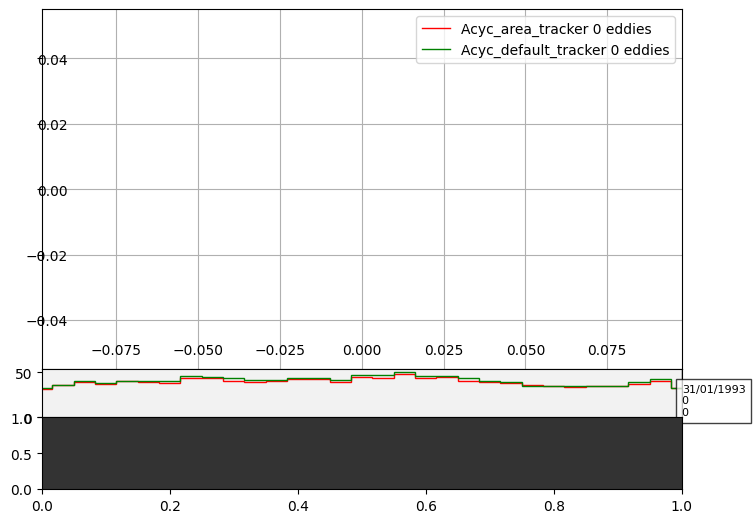

In [49]:
g = GUI(
    Acyc_area_tracker=eddies_area_tracker, Acyc_default_tracker=eddies_default_tracker
)
# g.now = 22000
# g.bbox = 0, 9, 36, 40
g.adjust()
g.show()

In [99]:
dir(g)

['COLORS',
 'KEYTIME',
 '__class__',
 '__delattr__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__slots__',
 '__str__',
 '__subclasshook__',
 'adjust',
 'bbox',
 'd_indexs',
 'datasets',
 'draw',
 'event',
 'figure',
 'get_infos',
 'hide_path',
 'indexs',
 'keyboard',
 'last_event',
 'm',
 'map',
 'med',
 'move',
 'now',
 'param_ax',
 'period',
 'press',
 'release',
 'scroll',
 'set_initial_values',
 'settings',
 'setup',
 'show',
 'time_ax',
 'update']

TypeError: 'Axes' object is not callable

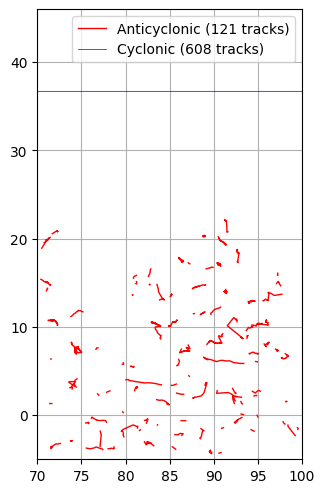

In [98]:
fig = plt.figure(figsize=(12, 5))
ax = fig.add_axes((0.05, 0.1, 0.9, 0.9))
ax.set_aspect("equal")
ax.set_xlim(70, 100), ax.set_ylim(-5, 46)
eddies_default_tracker.plot(ax, ref=-10, label="Anticyclonic ({nb_tracks} tracks)", color="r", lw=1)
eddies_area_tracker.plot(ax, ref=-10, label="Cyclonic ({nb_tracks} tracks)", color="b", lw=0.5)
ax.legend()
ax.grid()

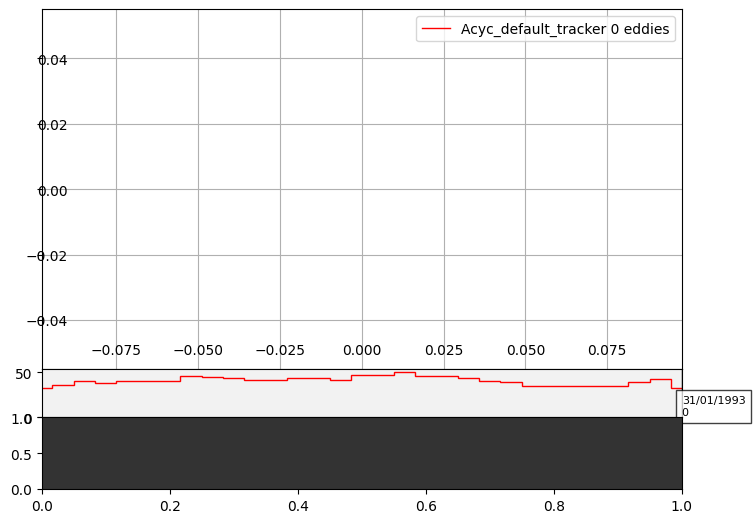

In [52]:
g = GUI(Acyc_default_tracker=eddies_default_tracker)
# g.now = 22000
# g.bbox = 0, 9, 36, 40
g.adjust()
g.show()

In [54]:
import re

from matplotlib.animation import FuncAnimation
from numpy import arange
# import py_eddy_tracker_sample

from py_eddy_tracker.appli.gui import Anim
from py_eddy_tracker.observations.tracking import TrackEddiesObservations

# sphinx_gallery_thumbnail_path = '_static/no_image.png'

In [58]:
dir(eddies_default_tracker)

['COLORS',
 'ELEMENTS',
 'NB_COLORS',
 'NOGROUP',
 '_TrackEddiesObservations__first_index_of_track',
 '_TrackEddiesObservations__nb_track',
 '_TrackEddiesObservations__obs_by_track',
 '__abstractmethods__',
 '__add__',
 '__class__',
 '__copy__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattr__',
 '__getattribute__',
 '__getitem__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__iter__',
 '__le__',
 '__len__',
 '__lt__',
 '__merge_filters__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__slots__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_abc_impl',
 '_repr_html_',
 'add_distance',
 'add_fields',
 'add_rotation_type',
 'age',
 'align_on',
 'amplitude',
 'append',
 'array_variables',
 'basic_formula_ellipse_major_axis',
 'bins_stat',
 'box_display',
 'build_var_list',
 'circle_contour',
 'close_tracks',
 'coherence',
 'compare_units',
 

In [120]:
id=eddies_default_tracker.index

In [123]:
print(str(id))

<bound method EddiesObservations.index of     | 1269 observations from 15706.0 to 15736.0 (31.0 days, ~41 obs/day)
    |   Speed area      : 0.94 Mkm²/day
    |   Effective area  : 1.24 Mkm²/day
    ----Distribution in Amplitude:
    |   Amplitude bounds (cm)        0.00      1.00      2.00      3.00      4.00      5.00     10.00    500.00
    |   Percent of eddies         :      25.85     21.83     10.24      5.12      6.93     20.17      9.85
    ----Distribution in Radius:
    |   Speed radius (km)            0.00     15.00     30.00     45.00     60.00     75.00    100.00    200.00   2000.00
    |   Percent of eddies         :       0.00      2.36     16.86     17.65     15.68     21.91     23.48      2.05
    |   Effective radius (km)        0.00     15.00     30.00     45.00     60.00     75.00    100.00    200.00   2000.00
    |   Percent of eddies         :       0.00      2.05     14.58     15.68     14.34     16.08     34.36      2.92
    ----Distribution in Latitude
        

c:\Users\53150\miniconda3\envs\eddy2\lib\site-packages\py_eddy_tracker\observations\observation.py:302: RuntimeWarning: invalid value encountered in true_divide
  v /= hist_numba(x, bins=bins)[0]


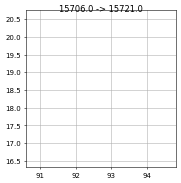

In [109]:
eddy = eddies_default_tracker.extract_ids([1])
a = Anim(eddy, intern=True, figsize=(8, 3.5), cmap="magma_r", nb_step=5, dpi=50)
a.txt.set_position((17, 34.6))
# a.ax.set_xlim(16.5, 23)
# a.ax.set_ylim(34.5, 37)

# arguments to get full animation
kwargs = dict(frames=arange(*a.period)[300:800], interval=90)

ani = VideoAnimation(a.fig, a.func_animation, **kwargs)

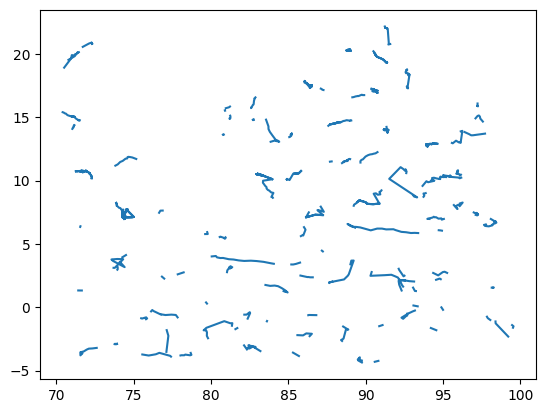

In [61]:
eddies_default_tracker.plot(plt.gca())

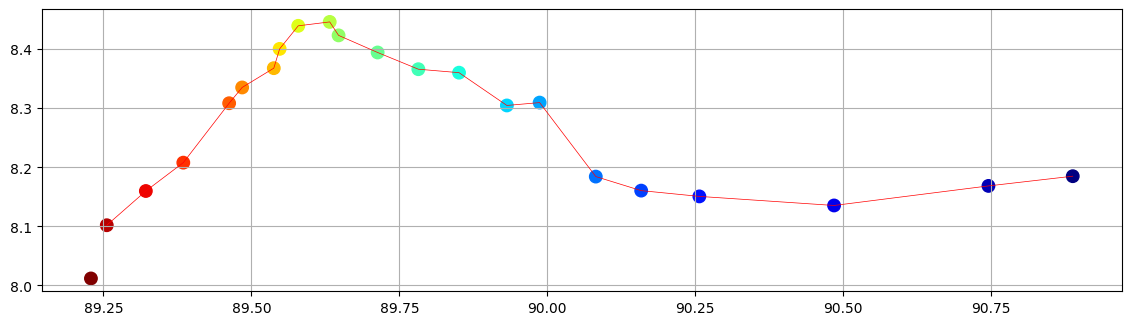

In [115]:
fig = plt.figure(figsize=(12, 5))
ax = fig.add_axes((0.05, 0.05, 0.9, 0.9))
# ax.set_xlim(17.5, 22)
# ax.set_ylim(35, 36.5)
ax.set_aspect("equal")
ax.grid()
eddies_default_tracker.extract_ids([2]).plot(ax, color="r", lw=0.5)
eddies_default_tracker.extract_ids([2]).scatter(ax, "n", cmap="jet", s=80)

In [62]:
from py_eddy_tracker.data import get_remote_demo_sample
from py_eddy_tracker.featured_tracking.area_tracker import AreaTracker
from py_eddy_tracker.gui import GUI
from py_eddy_tracker.tracking import Correspondances
file_objects = get_remote_demo_sample(
    "eddies_med_adt_allsat_dt2018/Anticyclonic_2010_2011_2012"
)[:180]
c = Correspondances(datasets=file_objects, class_method=AreaTracker, virtual=3)
c.track()
c.prepare_merging()
# We have now an eddy object
eddies_area_tracker = c.merge(raw_data=False)
eddies_area_tracker.virtual[:] = eddies_area_tracker.time == 0
eddies_area_tracker.filled_by_interpolation(eddies_area_tracker.virtual == 1)

File was created with py-eddy-tracker version 'None' but software version is '3.6'
File was created with py-eddy-tracker version 'None' but software version is '3.6'
File was created with py-eddy-tracker version 'None' but software version is '3.6'
File was created with py-eddy-tracker version 'None' but software version is '3.6'
File was created with py-eddy-tracker version 'None' but software version is '3.6'
File was created with py-eddy-tracker version 'None' but software version is '3.6'
File was created with py-eddy-tracker version 'None' but software version is '3.6'
File was created with py-eddy-tracker version 'None' but software version is '3.6'
File was created with py-eddy-tracker version 'None' but software version is '3.6'
File was created with py-eddy-tracker version 'None' but software version is '3.6'
File was created with py-eddy-tracker version 'None' but software version is '3.6'
File was created with py-eddy-tracker version 'None' but software version is '3.6'
File

In [69]:
ds=Dataset('test.nc')

In [70]:
ds.variables.keys()

dict_keys(['amplitude', 'cost_association', 'effective_area', 'effective_contour_height', 'effective_contour_latitude', 'effective_contour_longitude', 'effective_contour_shape_error', 'effective_radius', 'inner_contour_height', 'latitude', 'latitude_max', 'longitude', 'longitude_max', 'num_contours', 'num_point_e', 'num_point_s', 'observation_flag', 'observation_number', 'speed_area', 'speed_average', 'speed_contour_height', 'speed_contour_latitude', 'speed_contour_longitude', 'speed_contour_shape_error', 'speed_radius', 'time', 'track', 'uavg_profile'])

In [72]:
track=np.array(ds.variables['track'])

In [83]:
dir(ds[i])

['__array__',
 '__class__',
 '__delattr__',
 '__delitem__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattr__',
 '__getattribute__',
 '__getitem__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__len__',
 '__lt__',
 '__ne__',
 '__new__',
 '__orthogonal_indexing__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__setitem__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__unicode__',
 '_assign_vlen',
 '_check_safecast',
 '_cmptype',
 '_enumtype',
 '_get',
 '_getdims',
 '_getname',
 '_grp',
 '_grpid',
 '_has_lsd',
 '_iscompound',
 '_isenum',
 '_isprimitive',
 '_isvlen',
 '_name',
 '_ncstring_attrs__',
 '_nunlimdim',
 '_pack',
 '_put',
 '_toma',
 '_use_get_vars',
 '_varid',
 '_vltype',
 'add_offset',
 'always_mask',
 'assignValue',
 'chartostring',
 'chunking',
 'comment',
 'datatype',
 'delncattr',
 'dimensions',
 'dtype',
 'endian',
 'filters',
 'getValue',
 'get_dims',
 'get_var_chunk_cache',
 'getncattr',
 'grou

In [84]:
for i in ds.variables.keys():
    print(i,end='|')
    if i in ['crs','lat_bnds','lon_bnds']:
        print()
        continue
    else:
        print(f"{ds[i].name}:{ds[i].long_name}|",end='')
    try:
        print(f"{ds[i].shape}|")
    except:
        print('')

amplitude|amplitude:Amplitude|(10566,)|
cost_association|cost_association:Cost association between two eddies|(10566,)|
effective_area|effective_area:Effective area|(10566,)|
effective_contour_height|effective_contour_height:Effective Contour Height|(10566,)|
effective_contour_latitude|effective_contour_latitude:Effective Contour Latitudes|(10566, 50)|
effective_contour_longitude|effective_contour_longitude:Effective Contour Longitudes|(10566, 50)|
effective_contour_shape_error|effective_contour_shape_error:Effective Contour Shape Error|(10566,)|
effective_radius|effective_radius:Effective Radius|(10566,)|
inner_contour_height|inner_contour_height:Inner Contour Height|(10566,)|
latitude|latitude:Eddy Center Latitude|(10566,)|
latitude_max|latitude_max:Latitude of the SSH maximum|(10566,)|
longitude|longitude:Eddy Center Longitude|(10566,)|
longitude_max|longitude_max:Longitude of the SSH maximum|(10566,)|
num_contours|num_contours:Number of contours|(10566,)|
num_point_e|num_point_e:nu

In [124]:
'{:}/AC.req.{:}.nc'.format(dirAC, datestr)

'./Data/output/sla.AC.t001/AC.req.19930101.nc'